<a href="https://colab.research.google.com/github/sabbirpuspo/LearningforMe/blob/main/SkillMorph_16_Transfer_Learning_ResNet_DenseNet_Data_Science_3rd_batch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Transfer Learning with ResNet50 & DenseNet121

**Instructor:** Md. Samiul Islam, Skill Morph Research Lab

**What we will do:**
1. Load a plant disease dataset (healthy vs diseased)
2. Build models using pre-trained **ResNet50** and **DenseNet121**
3. Train, evaluate, and compare both models

---

**Key Idea — Transfer Learning:**
Instead of training a huge model from scratch (which needs lots of data + time),
we take a model already trained on **ImageNet** (14 million images!) and fine-tune
it for our small dataset. Think of it like hiring an experienced doctor and just
teaching them about local diseases — much faster than training a new doctor from zero!

## Step 1: Import Libraries

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Step 2: Load Dataset from Google Drive

**Dataset structure:**
```
PlantVillage_binary/
    train/
        diseased/
        healthy/
    test/
        diseased/
        healthy/
```

In [2]:
from google.colab import drive
drive.mount('/content/drive')

# ─── CHANGE THIS PATH to match your Drive ───
dataset_path = "/content/drive/MyDrive/PlantVillage_binary"

IMG_SIZE  = (224, 224)   # standard input size for ResNet / DenseNet
BATCH     = 32
EPOCHS    = 5

Mounted at /content/drive


In [3]:
# Load data
train_ds = keras.utils.image_dataset_from_directory(
    dataset_path + "/train", image_size=IMG_SIZE,
    batch_size=BATCH, label_mode='categorical')

test_ds = keras.utils.image_dataset_from_directory(
    dataset_path + "/test", image_size=IMG_SIZE,
    batch_size=BATCH, label_mode='categorical')

class_names = train_ds.class_names
num_classes = len(class_names)
print(f"Classes: {class_names}  |  Count: {num_classes}")

# Normalize pixels to [0, 1] and optimize loading
train_ds = train_ds.map(lambda x, y: (x / 255.0, y)).cache().prefetch(tf.data.AUTOTUNE)
test_ds  = test_ds.map(lambda x, y: (x / 255.0, y)).cache().prefetch(tf.data.AUTOTUNE)

Found 30 files belonging to 2 classes.
Found 10 files belonging to 2 classes.
Classes: ['diseased', 'healthy']  |  Count: 2


## Step 3: Visualize Sample Images

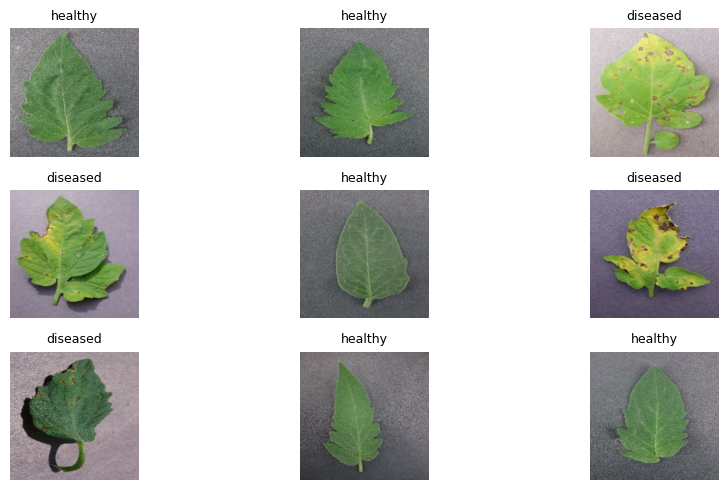

In [4]:
plt.figure(figsize=(10, 5))
for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(class_names[np.argmax(labels[i])], fontsize=9)
        plt.axis('off')
plt.tight_layout()
plt.show()

## Step 4: Build Both Models (ResNet50 & DenseNet121)

| Feature | ResNet50 | DenseNet121 |
|---------|----------|-------------|
| Full name | Residual Network | Densely Connected Network |
| Layers | 50 | 121 |
| Key idea | **Skip connections** — lets gradients flow through shortcuts | **Dense connections** — every layer talks to all previous layers |
| Benefit | Can train very deep networks without vanishing gradients | Better feature reuse, fewer parameters |

We write **one helper function** to avoid repeating code:

In [5]:
def build_model(base_model_class, name):
    """Build a transfer learning model from any Keras application."""
    base = base_model_class(
        include_top=False,          # remove original classifier head
        weights="imagenet",         # use pre-trained ImageNet weights
        input_shape=IMG_SIZE + (3,) # 224 x 224 x 3
    )
    base.trainable = False          # freeze all pre-trained layers

    model = models.Sequential([
        base,
        layers.GlobalAveragePooling2D(),        # compress feature maps
        layers.Dense(256, activation='relu'),    # new hidden layer
        layers.Dropout(0.5),                     # prevent overfitting
        layers.Dense(num_classes, activation='softmax')  # output
    ], name=name)

    model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# Build both models in two lines!
resnet_model   = build_model(keras.applications.ResNet50,    "ResNet50")
densenet_model = build_model(keras.applications.DenseNet121, "DenseNet121")



94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


## Step 5: Train Both Models

In [6]:
print(">>> Training ResNet50...")
resnet_hist = resnet_model.fit(train_ds, epochs=EPOCHS)

print("\n>>> Training DenseNet121...")
densenet_hist = densenet_model.fit(train_ds, epochs=EPOCHS)

>>> Training ResNet50...
Epoch 1/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 24s 24s/step - accuracy: 0.5333 - loss: 0.7040
Epoch 2/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.5000 - loss: 0.7989
Epoch 3/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.3667 - loss: 1.0153
Epoch 4/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.5333 - loss: 0.7778
Epoch 5/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - accuracy: 0.6000 - loss: 0.7178

>>> Training DenseNet121...
Epoch 1/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 65s 65s/step - accuracy: 0.4333 - loss: 1.0551
Epoch 2/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 30s 30s/step - accuracy: 0.7333 - loss: 0.6175
Epoch 3/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.9667 - loss: 0.2443
Epoch 4/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9333 - loss: 0.2309
Epoch 5/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 1.0000 - loss: 0.0817


## Step 6: Evaluate & Compare on Test Data

In [7]:
def evaluate(model, dataset, name):
    """Evaluate model and print detailed metrics."""
    loss, acc = model.evaluate(dataset, verbose=0)

    y_true, y_pred = [], []
    for imgs, lbls in dataset:
        preds = model.predict(imgs, verbose=0)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(np.argmax(lbls.numpy(), axis=1))

    print(f"\n{'=' * 45}")
    print(f"  {name}  —  Loss: {loss:.4f}  |  Accuracy: {acc:.4f}")
    print(f"{'=' * 45}")
    print(classification_report(y_true, y_pred, target_names=class_names))
    return {'loss': loss, 'accuracy': acc}

r = evaluate(resnet_model,   test_ds, "ResNet50")
d = evaluate(densenet_model, test_ds, "DenseNet121")

# Quick comparison table
print(f"\n{'Metric':<12} {'ResNet50':<12} {'DenseNet121':<12}")
print("-" * 36)
for k in ['accuracy', 'loss']:
    print(f"{k.title():<12} {r[k]:<12.4f} {d[k]:<12.4f}")


  ResNet50  —  Loss: 0.6835  |  Accuracy: 0.5000
              precision    recall  f1-score   support

    diseased       0.50      1.00      0.67         5
     healthy       0.00      0.00      0.00         5

    accuracy                           0.50        10
   macro avg       0.25      0.50      0.33        10
weighted avg       0.25      0.50      0.33        10



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



  DenseNet121  —  Loss: 0.0363  |  Accuracy: 1.0000
              precision    recall  f1-score   support

    diseased       1.00      1.00      1.00         5
     healthy       1.00      1.00      1.00         5

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00        10


Metric       ResNet50     DenseNet121 
------------------------------------
Accuracy     0.5000       1.0000      
Loss         0.6835       0.0363      


## Step 7: Plot Training Curves

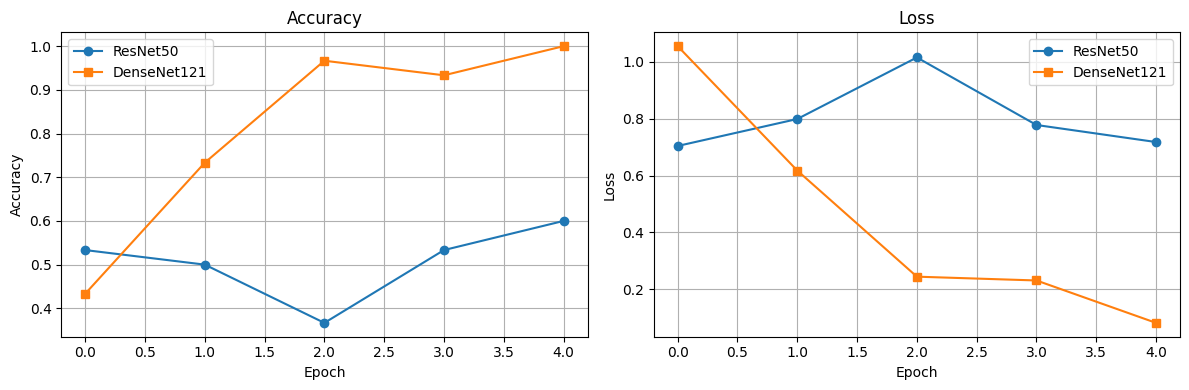

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

for ax, metric, title in [(ax1, 'accuracy', 'Accuracy'), (ax2, 'loss', 'Loss')]:
    ax.plot(resnet_hist.history[metric],   'o-', label='ResNet50')
    ax.plot(densenet_hist.history[metric],  's-', label='DenseNet121')
    ax.set_xlabel('Epoch'); ax.set_ylabel(title); ax.set_title(title)
    ax.legend(); ax.grid(True)

plt.tight_layout()
plt.show()

## Step 8: Visual Predictions on Test Images

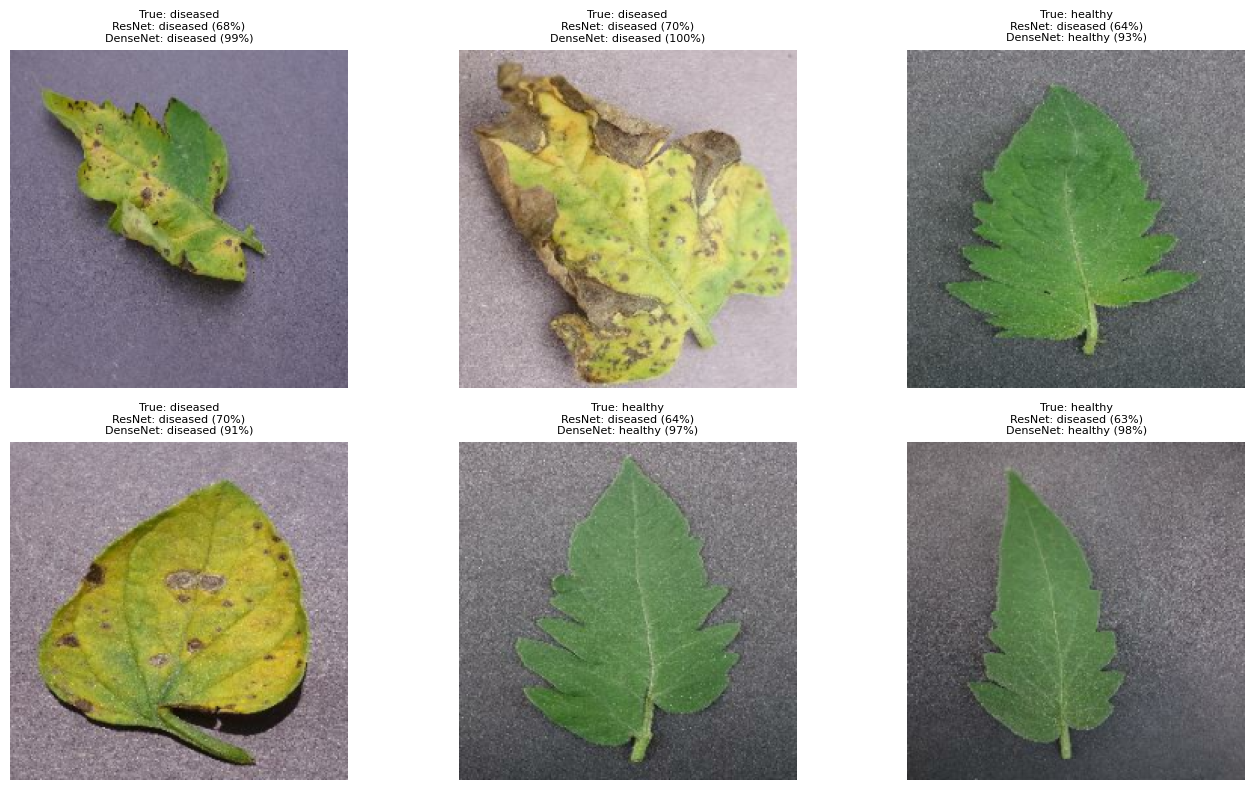

In [9]:
for test_imgs, test_lbls in test_ds.take(1):
    res_preds = resnet_model.predict(test_imgs, verbose=0)
    den_preds = densenet_model.predict(test_imgs, verbose=0)

    plt.figure(figsize=(14, 8))
    for i in range(min(6, len(test_imgs))):
        plt.subplot(2, 3, i + 1)
        plt.imshow(test_imgs[i].numpy())

        true  = class_names[np.argmax(test_lbls[i])]
        r_cls = class_names[np.argmax(res_preds[i])]
        d_cls = class_names[np.argmax(den_preds[i])]

        plt.title(f"True: {true}\n"
                  f"ResNet: {r_cls} ({np.max(res_preds[i])*100:.0f}%)\n"
                  f"DenseNet: {d_cls} ({np.max(den_preds[i])*100:.0f}%)",
                  fontsize=8)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

---
## Summary

| What we learned | Why it matters |
|-----------------|----------------|
| **Transfer Learning** | Train powerful models even with small datasets |
| **Freezing layers** | Keep pre-trained knowledge, only train new head |
| **ResNet50** | Skip connections help very deep networks learn |
| **DenseNet121** | Dense connections reuse features efficiently |
| **Comparison** | Always compare models — no single model is always best |

**Next steps to try:**
- Increase `EPOCHS` to 10–15 and observe improvement
- Unfreeze the last few layers of the base model (fine-tuning)
- Try other architectures: `MobileNetV2` (lightweight), `EfficientNetB0` (balanced)